# TP11 — Datastorytelling : état du marché

**But du notebook :** préparer progressivement le récit, les graphiques et le mini-deck du TP11. Complète les cellules Markdown vides après chaque étape. Ce notebook est un support de travail, pas le livrable de présentation final.

**Branche proposée :** `Klement/feat/tp11-datastorytelling`

**Périmètre à garder en tête :** l’EDA de référence porte sur un échantillon Open Food Facts de 8 400 produits après nettoyage minimal. Présente donc les observations comme des résultats sur cet échantillon, pas comme des estimations représentatives de tout le marché.

**Livrables TP11 :** mini-deck de 8 slides maximum et fonctions de tracé réutilisables dans `src/viz.py`.


## Fil conducteur

Pour chaque résultat, avance dans cet ordre : **message → chiffre vérifié → graphique → interprétation → limite → conséquence pour NutriScope**. Vise un deck de 7 slides, couverture comprise, puis ajuste si le récit l’exige.


## Étape 1 — Définir le récit et choisir les messages

**Objectif** — Sélectionner les 6 à 8 résultats de l’EDA qui aident la direction à comprendre l’échantillon et les enjeux NutriScope.

**À faire**

- [X] Définir le public et la conclusion générale à retenir.
- [X] Relire la synthèse TP10 et vérifier chaque chiffre dans le notebook de référence.
- [X] Choisir 6 à 8 messages maximum parmi les résultats sur les sucres, les grades, les rayons inconnus, la complétude, la qualité des données, les corrélations et les valeurs extrêmes.
- [X] Pour chaque message, noter le chiffre et son unité, la population concernée, la comparaison utile, une limite et la conséquence pour NutriScope.
- [X] Écarter les résultats trop techniques ou redondants.

**Résultat attendu** — Liste de messages vérifiés, prêts à devenir les titres des visuels.

**Commit associé** — `docs: define TP11 datastorytelling messages`

**Notes / rédaction**


> ### Public et angle du récit
>
> - **Public du deck :** la direction de NutriScope.
> - **Utilisateur auquel le récit se réfère :** un parent pressé qui veut comparer rapidement des produits pendant ses courses.
> - **Angle :** montrer ce que l’échantillon révèle sur les différences entre rayons, puis signaler les limites de classement et de complétude des données.
> - **Périmètre :** les résultats décrivent l’échantillon Open Food Facts après nettoyage minimal. Ils ne représentent pas nécessairement l’ensemble du marché alimentaire.
>
> ### Messages retenus
>
> #### 1. Les snacks sucrés se distinguent par leur teneur en sucres
>
> - **Chiffre et unité :** médiane de **38 g de sucres pour 100 g**, avec un premier quartile de 24 g et un troisième quartile de 53 g. La médiane du rayon suivant, les boissons, est de **6,1 g/100 g**.
> - **Population concernée :** produits avec un rayon connu et une valeur de sucres renseignée : **1 185 snacks sucrés** et **452 boissons**.
> - **Comparaison utile :** la médiane des snacks sucrés est environ six fois celle des boissons.
> - **Limite :** ces médianes décrivent les produits de l’échantillon et non chaque produit de ces rayons ni l’ensemble du marché.
> - **Conséquence pour NutriScope :** faciliter la comparaison des produits au sein de leur rayon et attirer l’attention sur les catégories particulièrement sucrées.
>
> #### 2. Les grades Nutri-Score varient fortement selon les rayons
>
> - **Chiffre et unité :** parmi les produits notés, **66,1 %** des snacks sucrés sont E et **50,3 %** des fruits et légumes sont A.
> - **Population concernée :** **5 149 produits** de rayon connu ayant un grade exploitable de A à E. Les snacks sucrés comptent **1 098 produits notés** et les fruits et légumes **344**.
> - **Comparaison utile :** les snacks sucrés et les fruits et légumes présentent des répartitions de grades très différentes.
> - **Limite :** les produits sans grade exploitable, notamment `unknown` et `not-applicable`, sont exclus. Le Nutri-Score ne décrit pas à lui seul tous les aspects nutritionnels d’un produit.
> - **Conséquence pour NutriScope :** présenter le grade avec le contexte du rayon et éviter d’en faire une évaluation complète du produit.
>
> #### 3. Un produit sur cinq n’a pas de rayon exploitable
>
> - **Chiffre et unité :** **1 726 produits sur 8 400**, soit **20,5 %**, n’ont pas de rayon connu.
> - **Population concernée :** l’ensemble des **8 400 produits** de l’échantillon après nettoyage minimal. Les 1 726 produits comprennent **1 700 produits classés `unknown`** et **26 sans valeur de rayon**.
> - **Comparaison utile :** seuls **6 674 produits** peuvent être utilisés dans les comparaisons par rayon.
> - **Limite :** les données utilisées pour cette EDA ne permettent pas encore de rattacher ces produits sans rayon aux catégories du Parquet.
> - **Conséquence pour NutriScope :** améliorer le classement des produits avant d’étendre les comparaisons à l’ensemble du catalogue.
>
> #### 4. La complétude des fiches varie selon les rayons
>
> - **Chiffre et unité :** **79,5 %** des fiches sont complètes pour les sept nutriments clés sur l’ensemble des rayons connus. Dix rayons se situent entre **71 % et 92 %** ; les boissons alcoolisées sont à **14 %**.
> - **Population concernée :** les **6 674 produits** dont le rayon est connu. Pour chaque produit, on vérifie si les sept nutriments clés sont renseignés. Les produits `unknown` ne sont pas inclus dans le résultat global par rayon.
> - **Comparaison utile :** la complétude n’est pas uniforme selon les rayons. Les fiches des boissons alcoolisées sont nettement moins complètes que celles de la plupart des autres rayons. Les aliments pour bébés montrent par ailleurs qu’une fiche complète ne garantit pas qu’un Nutri-Score soit disponible.
> - **Limite :** une fiche complète signifie que les sept valeurs sont présentes, pas qu’elles sont exactes. Les pourcentages par rayon reposent aussi sur des effectifs différents.
> - **Conséquence pour NutriScope :** afficher les informations manquantes et tenir compte de la complétude avant de comparer des produits ou des rayons.
>
> #### 5. Certains produits présentent un écart important avec le calcul d’énergie
>
> - **Chiffre et unité :** **119 produits sur 6 731**, soit environ **1,8 %**, ont un écart supérieur à **150 kcal/100 g** entre l’énergie déclarée et l’estimation 4/4/9. Parmi ces produits, 52 sont sous l’estimation et 67 au-dessus.
> - **Population concernée :** les **6 731 produits** pour lesquels l’énergie déclarée, les glucides, les protéines et les lipides sont tous renseignés.
> - **Comparaison utile :** la grande majorité des produits ayant les données nécessaires présente un écart inférieur ou égal au seuil de 150 kcal/100 g.
> - **Limite :** le calcul 4/4/9 est une estimation simplifiée, pas une valeur de référence parfaite. Un écart important signale un produit à examiner, mais ne prouve pas à lui seul une erreur.
> - **Conséquence pour NutriScope :** conserver des contrôles de cohérence et vérifier les fiches signalées avant de corriger ou d’écarter leurs valeurs.
>
> #### 6. Les valeurs extrêmes ne sont pas toutes des erreurs
>
> - **Chiffre et unité :** **1 371 produits sur 6 674**, soit **20,5 %**, ont au moins une valeur signalée comme extrême par rapport à leur rayon. Parmi les 15 cas les plus extrêmes relus manuellement, 9 sont jugés plausibles, 5 résiduels et 1 plausible mais associé à un rayon incorrect.
> - **Population concernée :** les **6 674 produits de rayon connu**. Le repérage porte sur les valeurs renseignées des nutriments analysés ; un produit est compté s’il possède au moins une valeur signalée.
> - **Comparaison utile :** le repérage statistique trouve des valeurs éloignées du profil de leur rayon, mais l’examen manuel montre que plusieurs correspondent à des produits plausibles.
> - **Limite :** la relecture ne porte que sur les 15 cas les plus extrêmes. Elle ne permet pas d’estimer la proportion d’erreurs parmi tous les produits signalés.
> - **Conséquence pour NutriScope :** utiliser ces seuils pour prioriser la vérification des données, pas pour supprimer automatiquement les produits concernés.
>
> ### Résultats écartés du récit principal
>
> - **Moyennes et médianes des sucres et du sel :** l’asymétrie des distributions justifie de privilégier médianes et quartiles, mais ce point est redondant avec le message sur les sucres. À garder comme explication de méthode dans la présentation.
> - **Corrélations entre nutriments et Nutri-Score :** elles sont surtout utiles pour préparer le modèle du TP14 et sont plus techniques que les autres messages. Elles ne seront pas dans le récit principal.
> - **V de Cramér de 0,34 :** il quantifie le lien entre rayon et grade, mais apporte peu de plus au graphique qui montre déjà la répartition des grades par rayon.
> - **Hypothèses bio/NOVA et autres tests exploratoires :** elles nécessitent davantage d’explications et ne sont pas prioritaires pour ce deck court.
> - **Complétude par marque :** les graphies de marques ne sont pas regroupées et les effectifs sont partiels. Ce résultat pourra être repris après normalisation.
> - **Point sur les “effectifs” et le sel :** écarté pour le moment, car sa formulation ne permet pas d’identifier clairement le résultat visé.
>
> ### Fil conducteur
>
> > L’échantillon révèle des différences marquées entre rayons, mais une part importante des produits est mal catégorisée ou incomplètement documentée. NutriScope devra donc associer la comparaison nutritionnelle à une information claire sur la qualité et les limites des données.

## Étape 2 — Choisir et concevoir les graphiques

**Objectif** — Associer un graphique lisible à chaque message, avec une seule idée par visuel.

**À faire**

- [ ] Choisir un type de graphique adapté à chaque message : comparaison, distribution, composition, relation ou cas extrêmes.
- [ ] Rédiger un titre qui annonce la conclusion.
- [ ] Prévoir axes, unités, ordre des catégories, légende, effectifs et source.
- [ ] Définir une charte simple et cohérente : couleurs, typographie, tailles et format d’export.
- [ ] Faire un croquis ou une première version de chaque visuel avant de finaliser le deck.

**Résultat attendu** — Maquette ou liste de spécifications des visuels retenus.

**Commit associé** — `docs: define TP11 chart specifications`

**Notes / rédaction**


In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Trouver la racine du dépôt, que le notebook soit lancé depuis
# le dossier du projet ou depuis notebooks/
RACINE = next(
    (
        chemin
        for chemin in [Path.cwd(), *Path.cwd().parents]
        if (chemin / "src" / "eda_lib.py").exists()
    ),
    None,
)

if RACINE is None:
    raise RuntimeError("Impossible de trouver la racine du dépôt NutriScope.")

if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

from src import eda_lib
from src.cleaning import lire_brut

# Couleurs utilisées par le graphique
BLEU = "#2a78d6"
GRIS = "#c3c2b7"
ENCRE = "#0b0b0b"

# Charger et préparer les données de l'EDA de référence
brut = lire_brut(RACINE / "data" / "echantillon_france.csv")
perimetre = eda_lib.nettoyage_minimal(brut)
par_rayon = eda_lib.rayons_connus(perimetre)

# Calculer les statistiques nécessaires au graphique
profil_sucres = eda_lib.profil_par_rayon(
    par_rayon,
    ["sugars_100g"],
).loc["sugars_100g"]

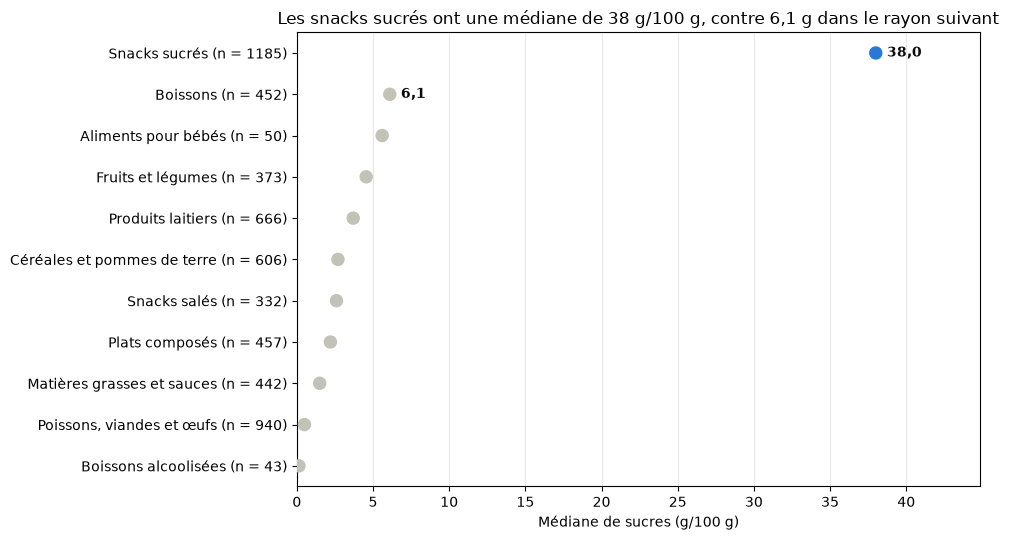

In [ ]:
# Sucres par rayon
import matplotlib.pyplot as plt
import numpy as np


def tracer_medianes_sucres(profil_sucres):
    """Trace la médiane de sucres par rayon, avec les effectifs disponibles.

    `profil_sucres` doit être la table de `profil.loc["sugars_100g"]`,
    avec les colonnes `mediane` et `n`, et les rayons en index.
    """
    donnees = (
        profil_sucres[["mediane", "n"]]
        .dropna(subset=["mediane"])
        .sort_values("mediane", ascending=False)
        .copy()
    )

    traductions = {
        "Sugary snacks": "Snacks sucrés",
        "Beverages": "Boissons",
        "Baby foods": "Aliments pour bébés",
        "Fruits and vegetables": "Fruits et légumes",
        "Milk and dairy products": "Produits laitiers",
        "Cereals and potatoes": "Céréales et pommes de terre",
        "Salty snacks": "Snacks salés",
        "Composite foods": "Plats composés",
        "Fat and sauces": "Matières grasses et sauces",
        "Fish Meat Eggs": "Poissons, viandes et œufs",
        "Alcoholic beverages": "Boissons alcoolisées",
    }

    couleurs = [
        BLEU if rayon == "Sugary snacks" else GRIS
        for rayon in donnees.index
    ]

    y = np.arange(len(donnees))
    fig, ax = plt.subplots(figsize=(10, 5.5))

    ax.scatter(
        donnees["mediane"],
        y,
        s=75,
        c=couleurs,
        zorder=3,
    )

    etiquettes = [
        f"{traductions.get(rayon, rayon)} (n = {int(effectif)})"
        for rayon, effectif in donnees["n"].items()
    ]
    ax.set_yticks(y, labels=etiquettes)
    ax.invert_yaxis()

    # Annoter les deux rayons mis en avant dans le message.
    for rayon in ["Sugary snacks", "Beverages"]:
        if rayon in donnees.index:
            valeur = donnees.loc[rayon, "mediane"]
            position_y = donnees.index.get_loc(rayon)
            ax.annotate(
                f"{valeur:.1f}".replace(".", ","),
                xy=(valeur, position_y),
                xytext=(8, 0),
                textcoords="offset points",
                va="center",
                fontweight="bold",
                color=ENCRE,
            )

    ax.set_title(
        "Les snacks sucrés ont une médiane de 38 g/100 g, "
        "contre 6,1 g dans le rayon suivant"
    )
    ax.set_xlabel("Médiane de sucres (g/100 g)")
    ax.set_ylabel("")
    ax.set_xlim(left=0, right=donnees["mediane"].max() * 1.18)
    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)

    fig.tight_layout()
    return fig, ax


fig, ax = tracer_medianes_sucres(profil_sucres)
plt.show()

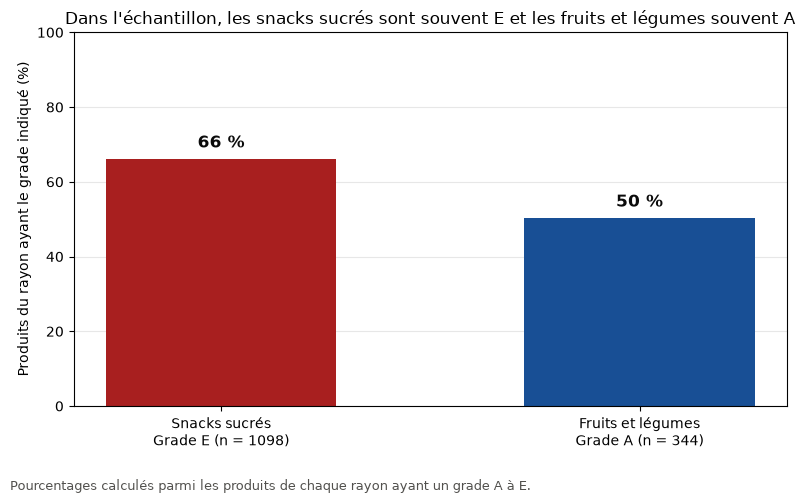

In [9]:
# Grades selon le rayon
import matplotlib.pyplot as plt


def tracer_grades_mis_en_avant(df):
    """Compare la part des grades E et A dans deux rayons de l'échantillon."""
    table = eda_lib.croisement_rayon_grade(df)

    donnees = [
        {
            "rayon": "Snacks sucrés",
            "nom_rayon": "Sugary snacks",
            "grade": "e",
            "couleur": "#a81f1f",
        },
        {
            "rayon": "Fruits et légumes",
            "nom_rayon": "Fruits and vegetables",
            "grade": "a",
            "couleur": "#184f95",
        },
    ]

    parts = []
    etiquettes = []
    couleurs = []

    for element in donnees:
        if element["nom_rayon"] not in table.index:
            raise ValueError(f"Rayon absent des données : {element['nom_rayon']}")

        effectif_note = int(table.loc[element["nom_rayon"]].sum())
        effectif_grade = int(table.loc[element["nom_rayon"], element["grade"]])
        pourcentage = effectif_grade / effectif_note * 100

        parts.append(pourcentage)
        etiquettes.append(
            f"{element['rayon']}\nGrade {element['grade'].upper()} (n = {effectif_note})"
        )
        couleurs.append(element["couleur"])

    fig, ax = plt.subplots(figsize=(8, 5))

    barres = ax.bar(
        etiquettes,
        parts,
        color=couleurs,
        width=0.55,
    )

    for barre, valeur in zip(barres, parts):
        ax.text(
            barre.get_x() + barre.get_width() / 2,
            valeur + 2,
            f"{valeur:.0f} %".replace(".", ","),
            ha="center",
            va="bottom",
            fontweight="bold",
            fontsize=12,
            color=ENCRE,
        )

    ax.set_ylim(0, 100)
    ax.set_ylabel("Produits du rayon ayant le grade indiqué (%)")
    ax.set_title(
        "Dans l'échantillon, les snacks sucrés sont souvent E "
        "et les fruits et légumes souvent A"
    )
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

    fig.text(
        0.01,
        0.01,
        "Pourcentages calculés parmi les produits de chaque rayon ayant un grade A à E.",
        ha="left",
        fontsize=9,
        color="#52514e",
    )

    fig.tight_layout(rect=(0, 0.06, 1, 1))
    return fig, ax


fig, ax = tracer_grades_mis_en_avant(par_rayon)
plt.show()

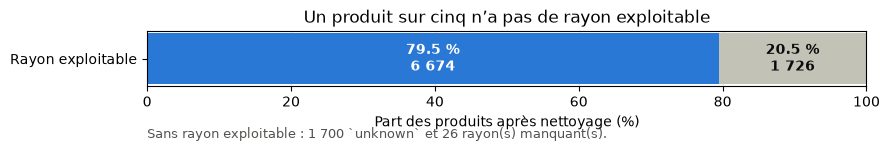

In [10]:
# Produits sans rayon exploitable
import matplotlib.pyplot as plt
import numpy as np


def tracer_couverture_rayons(produits):
    """Montre la part des produits avec et sans rayon exploitable."""
    colonne_rayon = eda_lib.RAYON
    total = len(produits)
    nombre_connus = len(eda_lib.rayons_connus(produits))
    nombre_unknown = int(
        produits[colonne_rayon].eq(eda_lib.RAYON_INCONNU).sum()
    )
    nombre_absents = int(produits[colonne_rayon].isna().sum())
    nombre_non_exploitables = total - nombre_connus

    # Vérifier que le groupe sans rayon exploitable est bien expliqué
    # par les catégories `unknown` et les valeurs manquantes.
    assert nombre_non_exploitables == nombre_unknown + nombre_absents

    part_connus = nombre_connus / total * 100
    part_non_exploitables = nombre_non_exploitables / total * 100

    fig, ax = plt.subplots(figsize=(9, 2.8))

    ax.barh(
        y=0,
        width=part_connus,
        color=BLEU,
        height=0.55,
    )
    ax.barh(
        y=0,
        width=part_non_exploitables,
        left=part_connus,
        color=GRIS,
        height=0.55,
    )

    ax.text(
        part_connus / 2,
        0,
        f"{part_connus:.1f} %\n{nombre_connus:,}".replace(",", " "),
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
    )
    ax.text(
        part_connus + part_non_exploitables / 2,
        0,
        f"{part_non_exploitables:.1f} %\n{nombre_non_exploitables:,}".replace(",", " "),
        ha="center",
        va="center",
        color=ENCRE,
        fontweight="bold",
    )

    ax.set_xlim(0, 100)
    ax.set_xticks(np.arange(0, 101, 20))
    ax.set_xlabel("Part des produits après nettoyage (%)")
    ax.set_yticks([0], labels=["Rayon exploitable"])
    ax.set_title("Un produit sur cinq n’a pas de rayon exploitable")

    ax.text(
        0,
        -0.75,
        f"Sans rayon exploitable : {nombre_unknown:,} `unknown` "
        f"et {nombre_absents} rayon(s) manquant(s).".replace(",", " "),
        transform=ax.transData,
        ha="left",
        va="top",
        fontsize=9,
        color="#52514e",
    )

    ax.grid(axis="x", alpha=0.3)
    ax.set_axisbelow(True)
    fig.tight_layout()

    return fig, ax


fig, ax = tracer_couverture_rayons(perimetre)
plt.show()

In [ ]:
# Complétude des fiches


In [ ]:
# Écarts d’énergie


In [ ]:
# Extrêmes plausibles ou résiduels

## Étape 3 — Créer les fonctions réutilisables dans `src/viz.py`

**Objectif** — Factoriser les fonctions de tracé pour permettre leur réutilisation dans le futur tableau de bord.

**À faire**

- [ ] Inspecter les dépendances, conventions et outils graphiques déjà présents dans le dépôt.
- [ ] Séparer calculs/analyse et rendu graphique ; éviter de dupliquer les calculs de l’EDA.
- [ ] Créer une fonction par famille de visuels retenue, avec des paramètres explicites et une charte commune.
- [ ] Permettre l’affichage et l’export des figures sans coupler les fonctions au deck.
- [ ] Vérifier que chaque fonction produit un visuel lisible avec les données et catégories attendues.

**Résultat attendu** — `src/viz.py` avec les fonctions correspondant aux graphiques du TP11.

**Commit associé** — `feat: add reusable market visualization functions`

**Notes / rédaction**


## Étape 4 — Assembler le mini-deck

**Objectif** — Construire une présentation cohérente de 8 slides maximum, adaptée à une restitution courte.

**À faire**

- [ ] Slide 1 : couverture, source et périmètre de l’échantillon.
- [ ] Slides suivantes : une conclusion principale par slide, avec son graphique et une interprétation courte.
- [ ] Inclure les limites nécessaires pour ne pas généraliser les résultats à tout le marché.
- [ ] Terminer par les implications pour NutriScope et les prochaines étapes du projet.
- [ ] Vérifier le fil narratif, la cohérence graphique et le nombre maximal de slides.

**Résultat attendu** — Mini-deck « État du marché » exporté dans un format présentable.

**Commit associé** — `docs: add NutriScope market state presentation`

**Notes / rédaction**


## Étape 5 — Préparer la présentation orale

**Objectif** — Présenter le récit en cinq minutes, seul, et être prêt à répondre aux questions.

**À faire**

- [ ] Préparer une ouverture courte sur la source, le périmètre et le message principal.
- [ ] Répartir le temps entre les résultats, les limites et la conclusion.
- [ ] Préparer pour chaque slide une explication : observation, intérêt, limite.
- [ ] Répéter avec un chronomètre et simplifier si le temps dépasse cinq minutes.

**Résultat attendu** — Trame orale de cinq minutes et durée vérifiée.

**Commit associé** — `Pas de commit requis sauf si la trame est conservée dans le dépôt.`

**Notes / rédaction**


## Étape 6 — Vérifier et finaliser les livrables

**Objectif** — S’assurer que le deck et les fonctions sont cohérents, lisibles et réutilisables.

**À faire**

- [ ] Vérifier les chiffres, unités, arrondis, effectifs et sources par rapport à l’EDA.
- [ ] Ouvrir le deck exporté et contrôler la lisibilité, les débordements et les légendes.
- [ ] Vérifier que les figures exportées sont suffisamment nettes et reproductibles.
- [ ] Relire les changements Git pour confirmer que seuls les fichiers du TP11 et la correction du cahier sont inclus.
- [ ] Préparer le commit final des ajustements de présentation.

**Résultat attendu** — Livrables prêts à être présentés et historique de commits compréhensible.

**Commit associé** — `docs: polish TP11 presentation assets`

**Notes / rédaction**


## Proposition de structure du deck

1. Couverture — état de l’échantillon et source.
2. Les snacks sucrés se distinguent par leur teneur en sucres.
3. La répartition des Nutri-Scores varie selon les rayons.
4. Un produit sur cinq n’a pas de rayon exploitable.
5. La complétude des fiches varie selon les rayons ou les marques.
6. Les données contiennent des incohérences, mais tous les extrêmes ne sont pas des erreurs.
7. Les résultats orientent les prochaines étapes de NutriScope.

Cette structure est un point de départ : conserve seulement les messages que les données permettent d’étayer clairement.


## Suivi des commits

- [ ] `docs: remove Utopios footer from TP cahier`
- [ ] `docs: define TP11 datastorytelling messages`
- [ ] `docs: define TP11 chart specifications`
- [ ] `feat: add reusable market visualization functions`

- [ ] `docs: add NutriScope market state presentation`
- [ ] `docs: polish TP11 presentation assets`
